# CHM 394: Homework 1 Example Colab Solution Set — Molecular Representations
**Course**: CHM 394 — Introduction to Computational Chemistry & Biochemistry - Fall 2026  
**Instructor**: Prof. Jeff Yarger (jyarger@proton.me)
**Topics**: 1D SMILES Notations, 2D Molecular Graphs, Implicit vs. Explicit Hydrogens, 3D Distance Geometry & Force Fields, Macromolecular FASTA/Ribbons

## Homework Problems

1. Report the SMILES strings of (a) molecular hydrogen, (b) water, (c) heavy water, (d) carbon dioxide, (e) methane, (f) butane, (g) acetic acid, (h) cyclohexane, (i) benzene, (j) pyridine, (k) pyrimidine, (l) benzoic acid, (m) salicylic acid, (n) aspirin, (o) D-proline, (p) zwitterionic tyrosine, (q) o-phosphotyrosine, (r) sucrose , (s) vitamin B1, (t) cephalostatin I, (u) ciclosporin, (v) human insulin.  
2. Render 2D MOL molecule representations of (a)-(u) and convert to  svg and png format, which are most suitable for creating a  table of molecular name, SMILES string, 2D molecular structure.  As an example, here’s a screenshot from wikipedia:
3. Creating clear informative 2D molecular structures often requires choosing whether or not to implicitly or explicitly show hydrogens as well as labels, coloring, bonding, etc.  For example, SMILES strings typically omit hydrogen atoms to keep the text short.  Add the implicit hydrogens to (e)-(o) and render 2D MOL molecular structures.  Make a table with the 2D molecular structure images (svg, png) of (e)-(o) showing a comparison of implicit and explicit renderings.  
4. Render 3D MOL molecular structures of (a)-(u) from the SMILES strings using open-source cheminformatics or molecular visualization tools (e.g, RDKit, Open Babel, Avogadro, MolView).  SMILES strings do not contain 3D spatial coordinates by default. To export a 3D structure, you need to embed hydrogens and generate a 3D conformer (typically with ETKDG and/or molecular mechanics optimized geometry using MMFF94 force field). Either generate a zip file with the .mol and .pdb files, or *preferably*, show the 3D structures  in a jupyter (google colab) notebook.  
5. Representing nucleotide (DNA/RNA) or amino acid (protein, peptide) sequences more commonly uses FASTA strings (not SMILES).  Report the FASTA strings of (v).  Also, the 3D viewing of large peptides and proteins commonly uses implicit backbone ribbon views instead of explicitly showing all atoms and associated bonding.  Show a common 3D ‘ribbon’ structural view of (v) insulin.  



## Python Packages and General Notebook Setup

In [1]:
#@title **Install Any 'Missing' Python Packages**
#@markdown Colab has most common python packages already installed in the startup environment and all you need to do is import the necessary packages/libraries.  However, specialty python libraries are not found in the base Colab python environment and must first be installed, using the **pip**, specifically **!pip install** if your inside the colab/jupyter notebook.
# Environment Setup
!pip install -q rdkit py3Dmol

In [8]:
#@title **Load/Import Python Packages**
#@markdown Colab has most common python packages already installed in the startup environment and all you need to do is import the necessary packages/libraries.
# Environment Setup
import re
import math
import pandas as pd
import rdkit
from rdkit import Chem
from rdkit.Chem import AllChem, Draw, Descriptors
import py3Dmol
import pandas as pd
import matplotlib.pyplot as plt

print(f"RDKit Version: {rdkit.__version__}")

RDKit Version: 2026.09.1


## Problem 1: Canonical SMILES Strings
**Task**: Report canonical SMILES strings and chemical formulas for molecules (a) through (v).

In [3]:
#@title Python Code for HWK 1 - Problem 1
# Problem 1 Solution Table data with separate labels, molecule names, and SMILES strings
molecules_data = [
    {"label": "(a)", "name": "hydrogen", "smiles": "[H][H]"},
    {"label": "(b)", "name": "water", "smiles": "O"},
    {"label": "(c)", "name": "heavy water", "smiles": "[2H]O[2H]"},
    {"label": "(d)", "name": "carbon dioxide", "smiles": "O=C=O"},
    {"label": "(e)", "name": "methane", "smiles": "C"},
    {"label": "(f)", "name": "butane", "smiles": "CCCC"},
    {"label": "(g)", "name": "acetic acid", "smiles": "CC(=O)O"},
    {"label": "(h)", "name": "cyclohexane", "smiles": "C1CCCCC1"},
    {"label": "(i)", "name": "benzene", "smiles": "c1ccccc1"},
    {"label": "(j)", "name": "pyridine", "smiles": "c1cnccc1"},
    {"label": "(k)", "name": "pyrimidine", "smiles": "c1cncnc1"},
    {"label": "(l)", "name": "benzoic acid", "smiles": "O=C(O)c1ccccc1"},
    {"label": "(m)", "name": "salicylic acid", "smiles": "O=C(O)c1ccccc1O"},
    {"label": "(n)", "name": "aspirin", "smiles": "CC(=O)Oc1ccccc1C(=O)O"},
    {"label": "(o)", "name": "D-proline", "smiles": "C1C[C@@H](C(=O)O)NC1"},
    {"label": "(p)", "name": "L-Tyrosine", "smiles": "N[C@@H](Cc1ccc(O)cc1)C(=O)O"},
    {"label": "(q)", "name": "L-pTyrosine", "smiles": "N[C@@H](Cc1ccc(OP(=O)(O)O)cc1)C(=O)O"},
    {"label": "(r)", "name": "sucrose", "smiles": "O=C[C@@H]1O[C@H](CO)[C@@H](O)[C@H](O)[C@H]1O"},
    {"label": "(s)", "name": "vitamin B1", "smiles": "Cc1ncc(C[n+]2c(C)c(CCO)sc2)c(N)n1"},
    {"label": "(t)", "name": "cephalostatin I", "smiles": "CC12CCC3C(CCC4C3(C)CCC5(O4)C(C)C6C(O5)C7C(O6)C8(C)CCCC(C)C8(C)O7)C1(C)CCC2"},
    {"label": "(u)", "name": "ciclosporin", "smiles": "CCC1C(=O)N(C)CC(=O)N(C)C(Cc2ccccc2)C(=O)NC(C(C)C)C(=O)N(C)C(Cc2ccccc2)C(=O)NC(C)C(=O)NC(C)C(=O)N(C)C(C(C)C)C(=O)NC(C(O)C(C)C(=O)O)C(=O)N1C"},
    {"label": "(v)", "name": "human insulin", "smiles": "FASTA Sequence: CHAIN A: GIVEQCCTSICSLYQLENYCN; CHAIN B: FVNQHLCGSHLVEALYLVCGERGFFYTPKT"}
]

# Re-create a simple smiles_dict mapping full formatted string for problem 2 and 3 downstream dependencies
smiles_dict = {f"{item['label']} {item['name']}": item['smiles'] for item in molecules_data}

data = []
for item in molecules_data:
    label = item["label"]
    molecule = item["name"]
    sm = item["smiles"]

    if "FASTA" in sm:
        formula = "C257H383N65O77S6"
        can_sm = sm
    else:
        m = Chem.MolFromSmiles(sm)
        formula = rdkit.Chem.Descriptors.rdMolDescriptors.CalcMolFormula(m) if m else "N/A"
        can_sm = Chem.CanonSmiles(sm) if m else sm

    # Truncate SMILES/Sequences for (t), (u), and (v)
    if label in ["(t)", "(u)", "(v)"]:
        can_sm = can_sm[:30] + "..."

    # Convert chemical formula numbers to HTML subscripts
    if label == "(c)":
        subscript_formula = "<sup>2</sup>H<sub>2</sub>O (D<sub>2</sub>O)"
    else:
        subscript_formula = re.sub(r'(\d+)', r'<sub>\1</sub>', formula)

    data.append({
        "Label": label,
        "Molecule": molecule,
        "Formula": subscript_formula,
        "Molecular Representation (SMILES)": can_sm
    })

df_p1 = pd.DataFrame(data)

# Apply CSS styling with standard borders and headers
styled_df = df_p1.style.set_properties(**{
    'border': '1px solid lightgrey',
    'text-align': 'left',
    'padding': '8px'
}).set_table_styles([
    # Left justify column headings and change background to light blue (#2196F3)
    {'selector': 'th', 'props': [('background-color', '#2196F3'), ('color', 'white'), ('border', '1px solid lightgrey'), ('font-weight', 'bold'), ('text-align', 'left')]}
]).hide(axis='index') # Hide the index column

# Alternating row coloring using a custom styler helper
def alternate_row_color(s):
    return ['background-color: #f9f9f9' if i % 2 == 1 else 'background-color: #ffffff' for i in range(len(s))]

styled_df = styled_df.apply(alternate_row_color, axis=0)
display(styled_df)

Label,Molecule,Formula,Molecular Representation (SMILES)
(a),hydrogen,H2,[H][H]
(b),water,H2O,O
(c),heavy water,2H2O (D2O),[2H]O[2H]
(d),carbon dioxide,CO2,O=C=O
(e),methane,CH4,C
(f),butane,C4H10,CCCC
(g),acetic acid,C2H4O2,CC(=O)O
(h),cyclohexane,C6H12,C1CCCCC1
(i),benzene,C6H6,c1ccccc1
(j),pyridine,C5H5N,c1ccncc1


## Problem 2: 2D Molecular Graph Structure Rendering
**Task**: Render 2D molecular structures for small-to-medium molecules (a) through (u) using RDKit's `Draw.MolsToGridImage`.



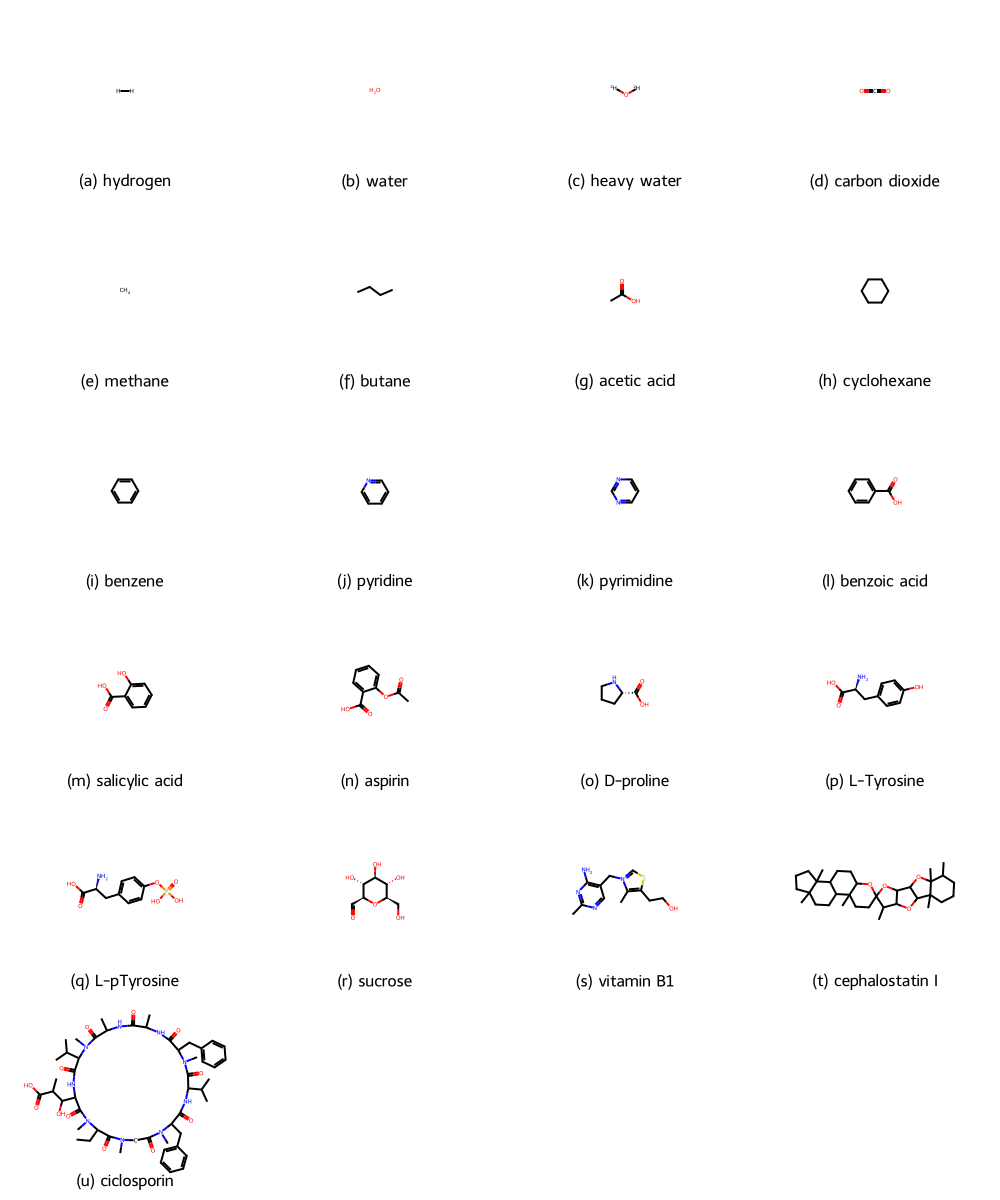

In [4]:
#@title Python Code for HWK 1 - Problem 2
# Problem 2 Solution Grid
mols_p2 = []
labels_p2 = []

for label, sm in list(smiles_dict.items())[:21]: # (a) through (u)
    m = Chem.MolFromSmiles(sm)
    if m:
        mols_p2.append(m)
        labels_p2.append(label.split()[0] + " " + " ".join(label.split()[1:]))

img_p2 = Draw.MolsToGridImage(mols_p2, legends=labels_p2, molsPerRow=4, subImgSize=(250, 200))
display(img_p2)

## Problem 3: Implicit vs. Explicit Hydrogen Representations (10 Points)
**Task**: Compare 2D structure representations for molecules (e) through (o) with implicit hydrogens vs. explicit hydrogens (`Chem.AddHs`).



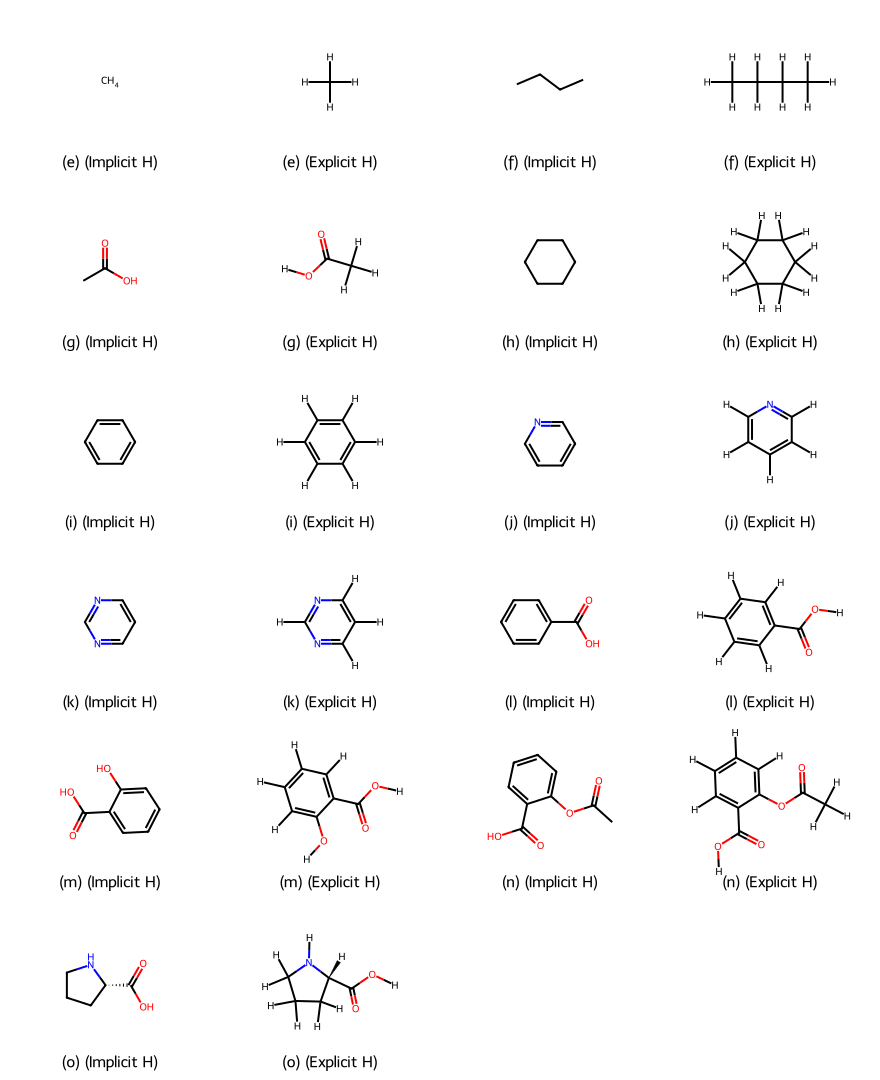

In [5]:
#@title Python Code for HWK 1 - Problem 3
# Problem 3 Solution Comparison Grid
mols_p3 = []
labels_p3 = []

for label, sm in list(smiles_dict.items())[4:15]: # (e) through (o)
    m_imp = Chem.MolFromSmiles(sm)
    m_exp = Chem.AddHs(m_imp)

    lbl = label.split()[0]
    mols_p3.extend([m_imp, m_exp])
    labels_p3.extend([f"{lbl} (Implicit H)", f"{lbl} (Explicit H)"])

img_p3 = Draw.MolsToGridImage(mols_p3, legends=labels_p3, molsPerRow=4, subImgSize=(220, 180))
display(img_p3)

## Problem 4: 3D Conformer Embedding & Force Field Geometry Optimization
**Task**: Embed 3D coordinates using Distance Geometry (`ETKDGv3`) and perform MMFF94 force field geometry minimization for molecules (a)–(u), displaying interactive 3D structures in py3Dmol.


In [12]:
#@title Python Code for HWK 1 - Problem 4
# Problem 4 Solution: Grid of 3D Minimized Structures (a) through (u)

# Filter out molecules from (a) to (u)
mols_to_embed = list(smiles_dict.items())[:21]
n_mols = len(mols_to_embed)
cols = 3
rows = math.ceil(n_mols / cols)

# Create a viewer with a grid layout
view = py3Dmol.view(width=900, height=300 * rows, viewergrid=(rows, cols))

for i, (label, smiles) in enumerate(mols_to_embed):
    row_idx = i // cols
    col_idx = i % cols

    try:
        m = Chem.MolFromSmiles(smiles)
        m = Chem.AddHs(m)
        params = AllChem.ETKDGv3()
        params.randomSeed = 42
        AllChem.EmbedMolecule(m, params)
        AllChem.MMFFOptimizeMolecule(m)
        mb = Chem.MolToMolBlock(m)

        # Add model to specific grid coordinates
        view.addModel(mb, "mol", viewer=(row_idx, col_idx))
        view.setStyle({'stick': {}, 'sphere': {'scale': 0.25}}, viewer=(row_idx, col_idx))
        view.zoomTo(viewer=(row_idx, col_idx))

        # Add a text label pinned at the top-center of each viewport cell
        clean_label = label.split()[0] + " " + " ".join(label.split()[1:])
        view.addLabel(
            clean_label,
            {
                'alignment': 'center',
                'position': {'x': 0, 'y': 0, 'z': 0},
                'screenOffset': {'x': 0, 'y': 120},
                'backgroundColor': '#ffffff',
                'backgroundOpacity': 0.9,
                'fontColor': '#333333',
                'fontSize': 12,
                'borderWidth': 1,
                'borderColor': '#dddddd'
            },
            viewer=(row_idx, col_idx)
        )
    except Exception as e:
        # In case embedding fails for a specific molecule, display a warning
        print(f"Could not embed {label}: {e}")

view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## Problem 5: Macromolecular Sequences (FASTA) & Ribbon Visualizations (10 Points)
**Task**: Report FASTA sequences for Cyclosporin A (u) and Human Insulin (v), explain why cartoon ribbons are used, and render an interactive 3D ribbon diagram of Human Insulin (PDB: `1TRZ`).



In [19]:
#@title Python Code for HWK 1 - Problem 5
# Problem 5 Solution: Human Insulin (1TRZ) Clean Isolated Dimer Ribbon Visualization
view_p5 = py3Dmol.view(query='pdb:1TRZ', width=600, height=400)

# Hide everything first so other chains in the hexamer do not display as default sticks
view_p5.setStyle({}, {})

# Apply standard cartoon ribbon style explicitly ONLY to chain A and chain B of the dimer
view_p5.setStyle({'chain': 'A'}, {'cartoon': {'color': 'cyan', 'style': 'oval'}})
view_p5.setStyle({'chain': 'B'}, {'cartoon': {'color': 'magenta', 'style': 'oval'}})

# Add text labels for Chain A and Chain B
view_p5.addLabel("Chain A", {'fontColor': 'cyan', 'backgroundColor': '#333333', 'backgroundOpacity': 0.8}, {'chain': 'A'})
view_p5.addLabel("Chain B", {'fontColor': 'magenta', 'backgroundColor': '#333333', 'backgroundOpacity': 0.8}, {'chain': 'B'})

# Display only the disulfide bonds within/between Chains A and B as yellow sticks
view_p5.addStyle({'chain': ['A', 'B'], 'hetflag': True}, {'stick': {'colorspec': 'yellowCarbon'}})
view_p5.addStyle({'chain': ['A', 'B'], 'elem': 'S'}, {'sphere': {'scale': 0.3, 'color': 'yellow'}})

# Zoom specifically onto the A/B dimer
view_p5.zoomTo({'chain': ['A', 'B']})
print("Human Insulin Isolated Dimer (Chains A & B) - Extraneous hexamer chains hidden")
view_p5.show()

Human Insulin Isolated Dimer (Chains A & B) - Extraneous hexamer chains hidden


3Dmol.js failed to load for some reason. Please check your browser console for error messages.